# 20251226 Feronia salinity time course samples (sc_291 ~ 294) integration with reference using Seurat 3
This runs within the scKB_copilot Conda environment


In [1]:
# Check the conda env running, it's important that you're running in the correct conda env
# Don't change anything here
Sys.getenv("CONDA_DEFAULT_ENV")

[1] "scKB_copilot"

In [2]:
# Check Seurat version, it's important that you're using the correct version of Seurat
# scKB_copilot: Seurat 3; seu4_label_transfer: Seurat 4; muscat: Seurat 5
# Don't change anything here
packageVersion("Seurat")

[1] ‘3.1.5’

In [3]:
# Clean the environment and set the directory
# Don't change anything here
rm(list=ls())
# NOTE: lab cluster path below -- change it to your own path
setwd("/resnick/groups/NolanLab/shared_resources/")

In [4]:
# Load the libraries
# Don't change anything here
suppressMessages(library(Seurat))
suppressMessages(library(tidyverse))
suppressMessages(library(dplyr))
suppressMessages(library(cowplot))
suppressMessages(library(data.table))
suppressMessages(library(RColorBrewer))
suppressMessages(library(grid))
suppressMessages(library(gplots))

In [5]:
# Check the loaded packages and their versions. 
# # Be sure to execute this! It's important for reproducibility and debugging
# Don't change anything here
sessionInfo()

R version 4.1.3 (2022-03-10)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: Red Hat Enterprise Linux 9.5 (Plow)

Matrix products: default
BLAS/LAPACK: /resnick/groups/NolanLab/cchen/miniconda3/envs/scKB_copilot/lib/libopenblasp-r0.3.29.so

locale:
 [1] LC_CTYPE=C.UTF-8           LC_NUMERIC=C              
 [3] LC_TIME=en_US.UTF-8        LC_COLLATE=en_US.UTF-8    
 [5] LC_MONETARY=en_US.UTF-8    LC_MESSAGES=en_US.UTF-8   
 [7] LC_PAPER=en_US.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=en_US.UTF-8 LC_IDENTIFICATION=C       

attached base packages:
[1] grid      stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] gplots_3.2.0       RColorBrewer_1.1-3 data.table_1.17.0  cowplot_1.1.3     
 [5] lubridate_1.9.4    forcats_1.0.0      stringr_1.5.0      dplyr_1.1.2       
 [9] purrr_1.0.1        readr_2.1.5        tidyr_1.3.0        tibble_3.2.1      
[13] g

In [6]:
# Load protoplast genes
# Don't change anything here
# NOTE: lab cluster path below -- change it to your own path
pp.genes <- as.character(read.table("/resnick/groups/NolanLab/shared_resources/source_files/Protoplasting_DEgene_FC2_list.txt", header=F)$V1)


## Update seu3 Object Metadata with Label Transfer Information
Cell annotation was performed using label transfer in Seurat 4. However, since Seurat 3 provides better visualization for single-cell data, we need to integrate the samples with the reference in Seurat 3. To achieve this, we must update the Seurat 3 objects (seu3) with the cell annotation information from the Seurat 4 objects.

In [13]:
# Seurat 3 Samples Requiring Metadata (Cell Annotation) Updates
# Change it to your samples
update.sample <- c("sc_291", "sc_292", "sc_293", "sc_294")

In [14]:
# Update the seurat 3 object metadata with label transfer cell annotation
# The output will be in annotated_objects/rds/individual folder
# Change the path to seu.v3, make sure the 10x version and species/genome is correct
# Don't change anything else
update_metadata <- function (sample.name) {
    
    # The seurat 3 object whose metadata we want to update 
    # NOTE: lab cluster path below -- change it to your own path
    seu.v3 <- read_seu(dir = paste0("/resnick/groups/NolanLab/shared_resources/annotated_objects/rds/individual/", sample.name, "_COPILOT.rds"))

    # The seurat 4 metadata with label transfer info
    new_metadata <- read.csv(file = paste0("annotated_objects/rds/individual/seu4_metadata/", sample.name,"_seu4_metadata.csv"),
                             header = TRUE)

    # Make sure the rownames of the metadata are the cell barcodes
    new_metadata <- new_metadata %>%
                column_to_rownames("X")

    # Update seurat 3 object metadata
    seu.v3@meta.data <- new_metadata

    # Save the updated seu3 object
    saveRDS(seu.v3, file = paste0("annotated_objects/rds/individual/", sample.name, "_COPILOT_seu3.rds"))
}


In [15]:
# Run update_metadata() through all samples
# Don't change anything here
for (i in 1:length(update.sample)){
    print(update.sample[i])
    update_metadata(update.sample[i])
}

[1] "sc_291"
[1] "sc_292"
[1] "sc_293"
[1] "sc_294"


## Samples integration with the reference
After updating the Seurat 3 objects, now we can integrate the samples.

In [16]:
# List all the samples for integration
# Replace the list with your samples. 
# Be sure to list the references (e.g., sc_12, dc1 and dc2)) before your samples, because we want to map our samples on to the references
use.sample <- c("sc_12", "dc1", "dc2", update.sample)

In [17]:
# Read in all samples for integration
# Don't change anything here
rc.list <- list()

for (i in 1:length(use.sample)) {
    rc.list[[i]] <- read_seu(dir = paste0("annotated_objects/rds/individual/",use.sample[i],"_COPILOT_seu3.rds"))
}

names(rc.list) <- use.sample

In [18]:
# Set nfeatures to the number greater than all possible gene numbers
# For example, Arabidopsis has ~26000 genes, so any number higher than this is fine
rc.features <- SelectIntegrationFeatures(object.list = rc.list, nfeatures = 40000)

# Check the number of genes in intersection
length(rc.features)

[1] 20217

In [19]:
# Mitochondrial, protoplast and chloroplast genes removal
# Don't change anything here
rc.features <- rc.features[-c(grep("ATMG",rc.features),grep("ATCG",rc.features),sort(match(pp.genes, rc.features)))]

# Check the number of genes after removal
# These will be the genes for integrating the sampels
length(rc.features)

[1] 17768

In [20]:
# Check the Seurat objects if they look fine
# Don't change anything here
rc.list

$sc_12
An object of class Seurat 
49648 features across 10293 samples within 2 assays 
Active assay: SCT (23357 features, 23357 variable features)
 1 other assay present: RNA
 2 dimensional reductions calculated: pca, umap

$dc1
An object of class Seurat 
47748 features across 3378 samples within 2 assays 
Active assay: SCT (21818 features, 21818 variable features)
 1 other assay present: RNA
 2 dimensional reductions calculated: pca, umap

$dc2
An object of class Seurat 
47752 features across 3283 samples within 2 assays 
Active assay: SCT (22007 features, 22007 variable features)
 1 other assay present: RNA
 2 dimensional reductions calculated: pca, umap

$sc_291
An object of class Seurat 
48973 features across 14059 samples within 2 assays 
Active assay: SCT (22789 features, 22789 variable features)
 1 other assay present: RNA
 2 dimensional reductions calculated: pca, umap

$sc_292
An object of class Seurat 
48552 features across 10304 samples within 2 assays 
Active assay: SCT (22

In [21]:
# Prepare an object list that has been run through SCTransform for integration
# Don't change anything here
rc.list <- PrepSCTIntegration(object.list = rc.list, anchor.features = rc.features, verbose = TRUE)

In [22]:
# Find a set of anchors between a list of Seurat objects. These anchors can later be used to integrate the objects using the IntegrateData function.
# reference = 1 means that the first sample in the sample list is used as the first reference. For example, here we're using # sc_12 as the reference for integration
# Don't change anything here
rc.anchors <- suppressMessages(FindIntegrationAnchors(object.list = rc.list, normalization.method = "SCT", 
    anchor.features = rc.features, verbose = TRUE, reference = 1))

Warning message in CheckDuplicateCellNames(object.list = object.list):
“Some cell names are duplicated across objects provided. Renaming to enforce unique cell names.”


In [23]:
# Perform dataset integration using a pre-computed AnchorSet
# Don't change anything here
rc.integrated <- IntegrateData(anchorset = rc.anchors, normalization.method = "SCT", verbose = TRUE)

Integrating dataset 2 with reference dataset

Finding integration vectors

Finding integration vector weights

Integrating data

Integrating dataset 3 with reference dataset

Finding integration vectors

Finding integration vector weights

Integrating data

Integrating dataset 4 with reference dataset

Finding integration vectors

Finding integration vector weights

Integrating data

Integrating dataset 5 with reference dataset

Finding integration vectors

Finding integration vector weights

Integrating data

Integrating dataset 6 with reference dataset

Finding integration vectors

Finding integration vector weights

Integrating data

Integrating dataset 7 with reference dataset

Finding integration vectors

Finding integration vector weights

Integrating data

Warning message:
“Adding a command log without an assay associated with it”


# Run PCA, UMAP and Clustering

In [ ]:
# Run PCA
# Don't change anything here unless you want different algorithm for FindClusters()
rc.integrated <- RunPCA(rc.integrated, npcs = 50, verbose = FALSE, approx = FALSE)

# Find nearest neighbors
rc.integrated <- FindNeighbors(rc.integrated, reduction = "pca",dims = 1:50)

# Clustering
# Notice that here we choose SLM algorithm with resoltion 5. 
# Algorithm: 1 = original Louvain algorithm; 2 = Louvain algorithm with multilevel refinement; 3 = SLM algorithm; 4 = Leiden algorithm
rc.integrated <- FindClusters(rc.integrated, resolution = 0.5, algorithm = 3)


In [ ]:
# Don't change anything here unless you want different number of neighhbors or components
# Run 3D UMAP
rc.integrated <- RunUMAP(rc.integrated, reduction = "pca", dims = 1:50, n.components = 3, n.neighbors = 30, min.dist=0.3)
rc.integrated@reductions$umap_3D <- rc.integrated@reductions$umap

# Run 2D UMAP
rc.integrated <- RunUMAP(rc.integrated, reduction = "pca", dims = 1:50, n.neighbors = 30, min.dist=0.3)
rc.integrated@reductions$umap_2D <- rc.integrated@reductions$umap

In [ ]:
# After saving the Seurat object, comment out this line for safety to prevent accidentally overwriting the saved file    
# Replace with your project name and date. For example, Xu2024_feronia is the study name, and 12S means 12 samples, and 20250126 is the date. 
#saveRDS(rc.integrated, file = "annotated_objects/rds/integrated/Feronia_salinity_timecourse_4S_20251226_seu3.rds")

In [28]:
# Check the integrated object
# Don't change anything here
rc.integrated

An object of class Seurat 
72086 features across 64998 samples within 3 assays 
Active assay: integrated (17768 features, 17768 variable features)
 2 other assays present: RNA, SCT
 4 dimensional reductions calculated: pca, umap, umap_3D, umap_2D

# Plotting

In [17]:
#rc.integrated <- readRDS("annotated_objects/rds/integrated/Feronia_salinity_timecourse_4S_20251226_seu3.rds")

In [29]:
# The plot function to plot UMAP
# Don't change anything here!
# Argument "rc.integrated" means a seurat object
plot_anno <- function(rc.integrated){
#rc.integrated$time.anno.Li.crude <- gsub("_.*$","",rc.integrated$time.celltype.anno.Li.crude)
#rc.integrated$celltype.anno.Li.crude <- gsub("Distal Columella","Distal Columella_Columella",rc.integrated$time.celltype.anno.Li.crude)
#rc.integrated$celltype.anno.Li.crude <- gsub("Distal Lateral Root Cap","Distal Lateral Root Cap_Lateral Root Cap",rc.integrated$celltype.anno.Li.crude)
#rc.integrated$celltype.anno.Li.crude <- gsub("Proximal Columella","Proximal Columella_Columella",rc.integrated$celltype.anno.Li.crude)
#rc.integrated$celltype.anno.Li.crude <- gsub("Proximal Lateral Root Cap","Proximal Lateral Root Cap_Lateral Root Cap",rc.integrated$celltype.anno.Li.crude)
#rc.integrated$celltype.anno.Li.crude <- gsub("^.*_","",rc.integrated$celltype.anno.Li.crude)

rc.integrated$time.anno.Li <- gsub("_.*$","",rc.integrated$time.celltype.anno.Li)
rc.integrated$celltype.anno.Li <- gsub("Distal Columella","Distal Columella_Columella",rc.integrated$time.celltype.anno.Li)
rc.integrated$celltype.anno.Li <- gsub("Distal Lateral Root Cap","Distal Lateral Root Cap_Lateral Root Cap",rc.integrated$celltype.anno.Li)
rc.integrated$celltype.anno.Li <- gsub("Proximal Columella","Proximal Columella_Columella",rc.integrated$celltype.anno.Li)
rc.integrated$celltype.anno.Li <- gsub("Proximal Lateral Root Cap","Proximal Lateral Root Cap_Lateral Root Cap",rc.integrated$celltype.anno.Li)
rc.integrated$celltype.anno.Li <- gsub("^.*_","",rc.integrated$celltype.anno.Li)
    
#order <- c("Quiescent Center", "Ground Tissue","Columella", "Lateral Root Cap", "Atrichoblast", "Trichoblast", "Cortex", "Endodermis", "Phloem","Protophloem", "Xylem", "Procambium","Pericycle","Phloem Pole Pericycle", "Protoxylem", "Metaxylem", "Unknown")
#palette <- c("#9400d3", "#DCD0FF","#5ab953", "#bfef45", "#008080", "#21B6A8", "#82b6ff", "#0000FF","#e6194b", "#dd77ec", "#9a6324", "#ffe119", "#ff9900", "#ffd4e3", "#9a6324", "#ddaa6f", "#EEEEEE")
#rc.integrated$celltype.anno.Li.crude <- factor(rc.integrated$celltype.anno.Li.crude, levels = order[sort(match(unique(rc.integrated$celltype.anno.Li.crude),order))]) 
#color <- palette[sort(match(unique(rc.integrated$celltype.anno.Li.crude),order))]

order <- c("Quiescent Center", "Ground Tissue","Columella", "Lateral Root Cap", "Atrichoblast", "Trichoblast", "Cortex", "Endodermis", "Metaphloem & Companion Cell","Protophloem", "Xylem", "Procambium","Xylem Pole Pericycle","Phloem Pole Pericycle", "Protoxylem", "Metaxylem", "Unknown")
palette <- c("#9400D3", "#DCD0FF","#5AB953", "#BFEF45", "#008080", "#21B6A8", "#82B6FF", "#0000FF","#E6194B", "#DD77EC", "#9A6324", "#FFE119", "#FF9900", "#FFD4E3", "#9A6324", "#DDAA6F", "#EEEEEE")

rc.integrated$celltype.anno.Li <- factor(rc.integrated$celltype.anno.Li, levels = order[sort(match(unique(rc.integrated$celltype.anno.Li),order))])
color <- palette[sort(match(unique(rc.integrated$celltype.anno.Li),order))]
                 
p1 <- DimPlot(rc.integrated, reduction = "umap", group.by = "celltype.anno.Li", cols=color)
p2 <- DimPlot(rc.integrated, reduction = "umap", group.by = "time.anno.Li", order = c("Distal Columella","Proximal Columella","Distal Lateral Root Cap","Proximal Lateral Root Cap","Maturation","Elongation", "Transition Domain", "Proliferation Domain"),
        cols = c('#F7E7B0','#FFC400','#2B871F','#005E3B',"#deebf7", "#3182bd", '#fee0d2','#de2d26'))
p3 <- DimPlot(rc.integrated, reduction = "umap", group.by = "consensus.time.group", cols=brewer.pal(10,"Spectral"))
p4 <- DimPlot(rc.integrated, reduction = "umap", group.by = "branch.anno")
options(repr.plot.width=18, repr.plot.height=12)
gl <- lapply(list(p1, p2, p3, p4), ggplotGrob)
gwidth <- do.call(unit.pmax, lapply(gl, "[[", "widths"))
gl <- lapply(gl, "[[<-", "widths", value = gwidth)
gridExtra::grid.arrange(grobs=gl, ncol=2)
return(rc.integrated)
}

In [33]:
# Flip the UMAP embedding coordinates along both the x-axis and y-axis to make the visualization better
# Don't change anything here
#rc.integrated[["umap"]]@cell.embeddings[,1] <- rc.integrated[["umap"]]@cell.embeddings[,1]*-1
#rc.integrated[["umap"]]@cell.embeddings[,2] <- rc.integrated[["umap"]]@cell.embeddings[,2]*-1
u2 <- rc.integrated@reductions$umap@cell.embeddings[,1]
u1 <- rc.integrated@reductions$umap@cell.embeddings[,2]
rc.integrated@reductions$umap@cell.embeddings[,1] <- u1
rc.integrated@reductions$umap@cell.embeddings[,2] <- u2

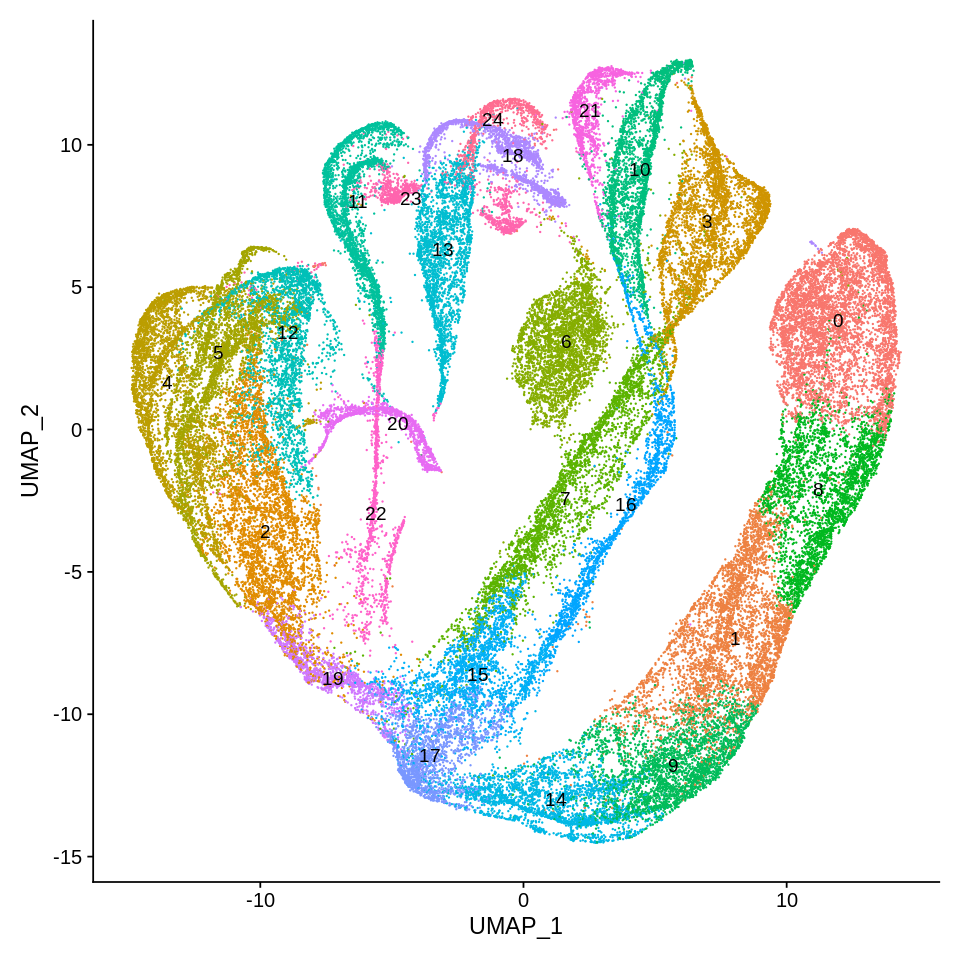

In [34]:
# Plot the UMAP with clustering numbers labelled
# You can adjust the width/height
options(repr.plot.width=8, repr.plot.height=8)
DimPlot(rc.integrated, label=TRUE)+NoLegend()

In [35]:
# Check how many cells are in each cluster
# Don't change anything here
table(rc.integrated$seurat_clusters)


   0    1    2    3    4    5    6    7    8    9   10   11   12   13   14   15 
5511 4103 3973 3856 3552 3519 3458 3181 3108 3107 2807 2717 2632 2575 2461 2406 
  16   17   18   19   20   21   22   23   24 
1858 1837 1729 1309 1207 1133 1097 1074  788 

In [36]:
# Check how many cells are in each sample
# Don't change anything here
table(rc.integrated$orig.ident)


   dc1    dc2  sc_12 sc_291 sc_292 sc_293 sc_294 
  3378   3283  10293  14059  10304  10939  12742 

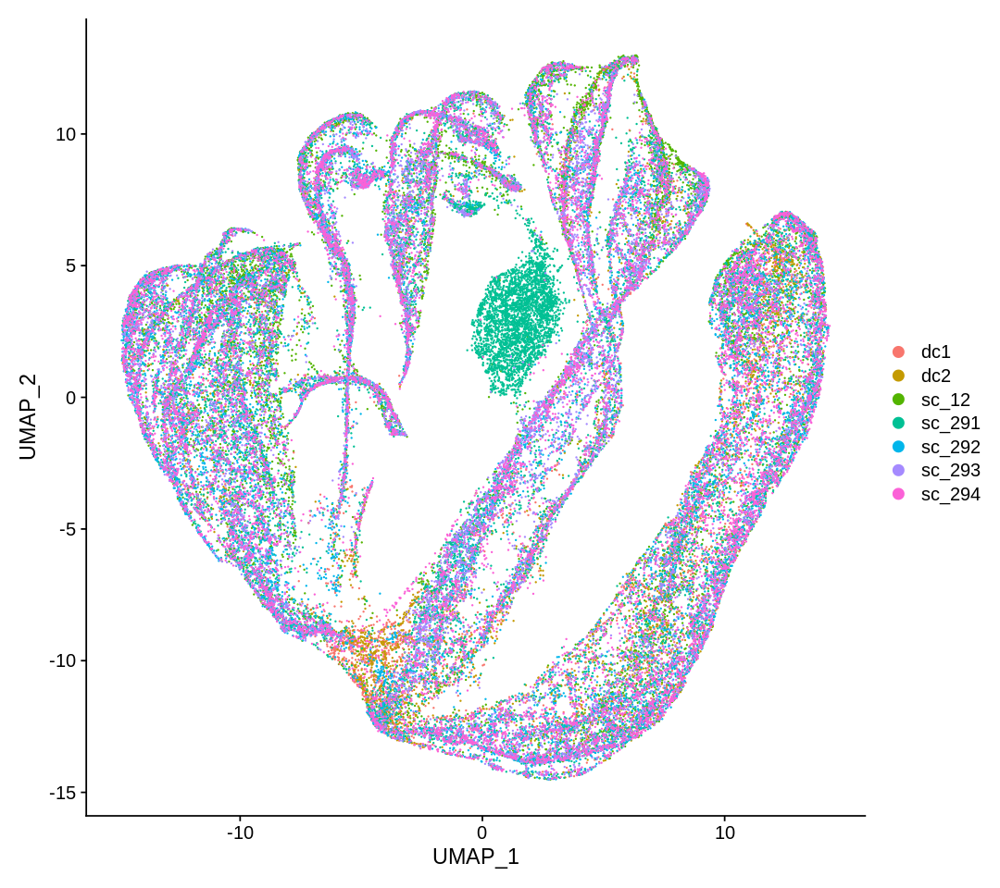

In [37]:
# Plot the UMAP with sample names labelled
# You can adjust the width/height
options(repr.plot.width=9, repr.plot.height=8)
DimPlot(rc.integrated, group.by = "orig.ident")

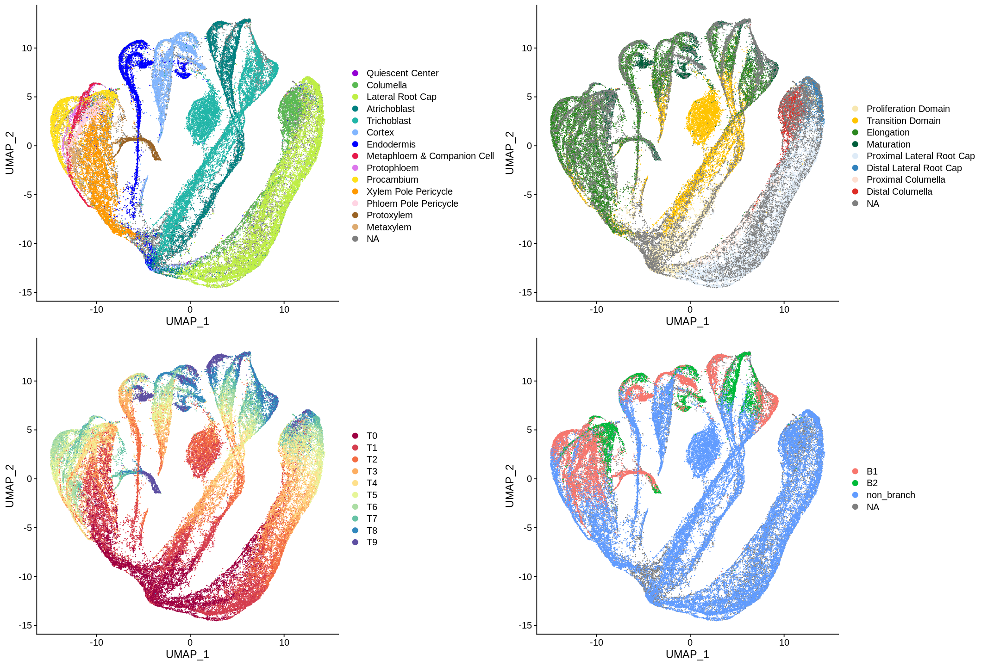

In [38]:
rc.integrated <- plot_anno(rc.integrated)

## Subset to include only the samples (exclude references)
Since we are primarily interested in analyzing our samples, we need to remove the reference data. The reference was included solely to maintain visualization consistency with our previously published root atlas.

In [39]:
# Select the samples only
# Change the sample names to fit your samples
rc.integrated_sub <- subset(rc.integrated, 
                        cells=colnames(rc.integrated)[which(rc.integrated$orig.ident %in% 
                                                            c("sc_291", "sc_292", "sc_293", "sc_294"))])



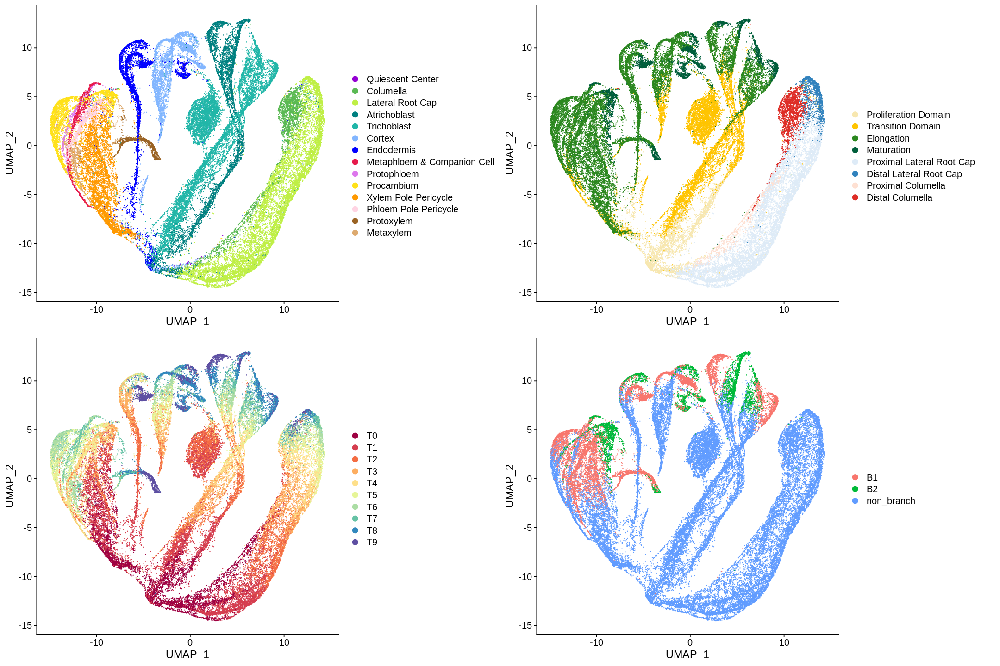

In [40]:
# Plot only the samples without reference
# Don't change anything here
rc.integrated_sub <- plot_anno(rc.integrated_sub)

In [104]:
# Use this to check the items in metadata if you'd like
#colnames(rc.integrated@meta.data)

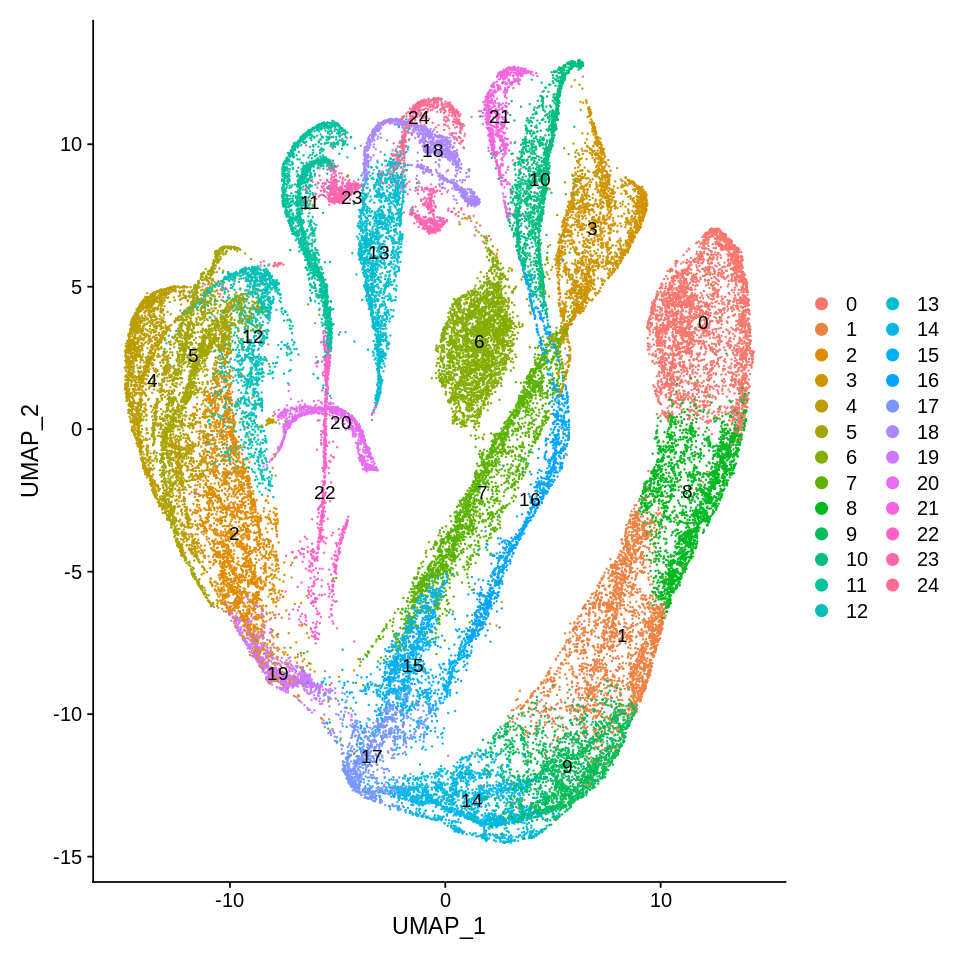

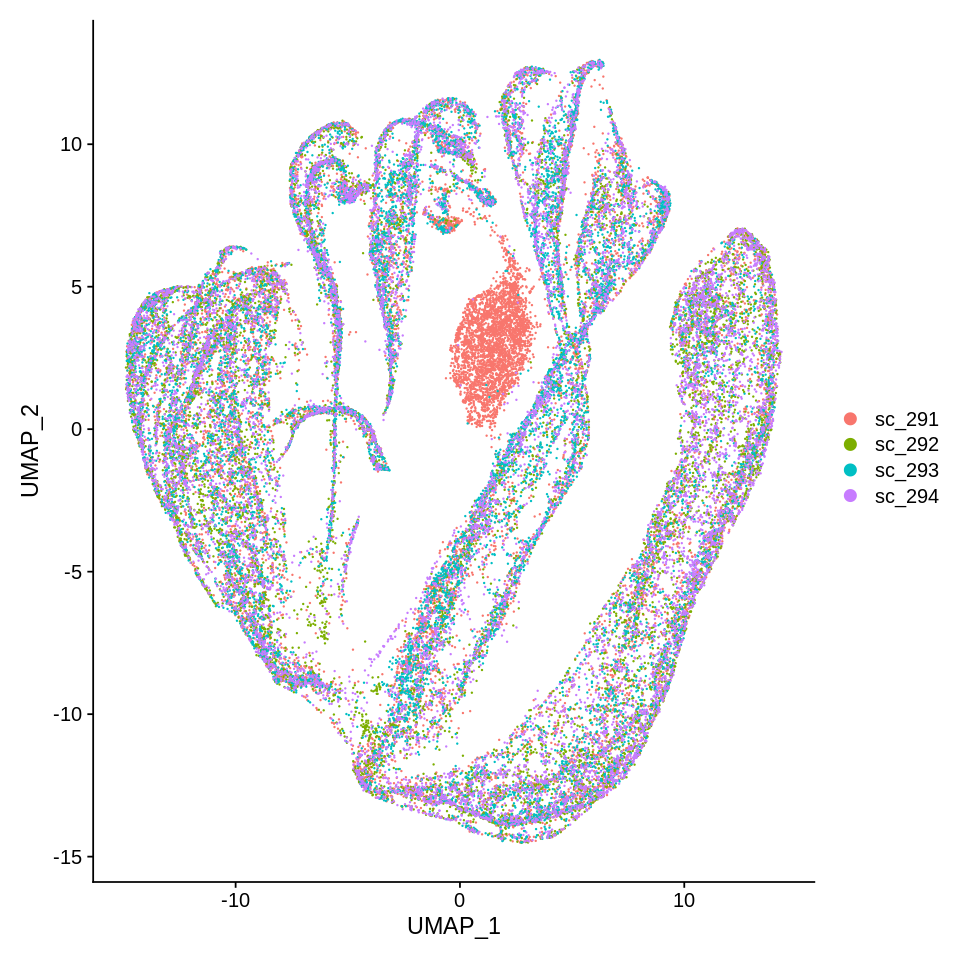

In [45]:
# There's a strange cluster
# cluster 6 is suspicious!
# And it's only in sc_291, which is known to have a suspicious cluster
options(repr.plot.width=8, repr.plot.height=8)
DimPlot(rc.integrated_sub, label=TRUE)

DimPlot(rc.integrated_sub, group.by = "orig.ident")

In [46]:
# Remove cluster 6
rc.integrated_sub <- subset(rc.integrated_sub, subset = seurat_clusters != 6)

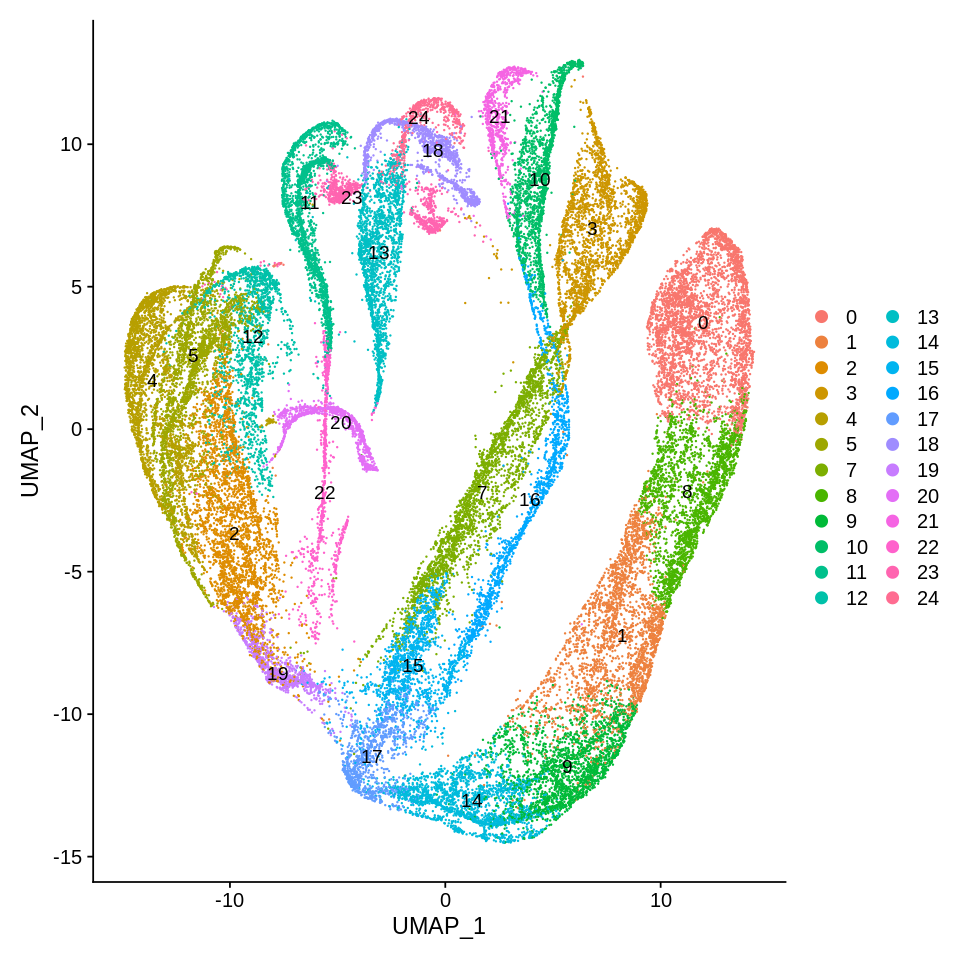

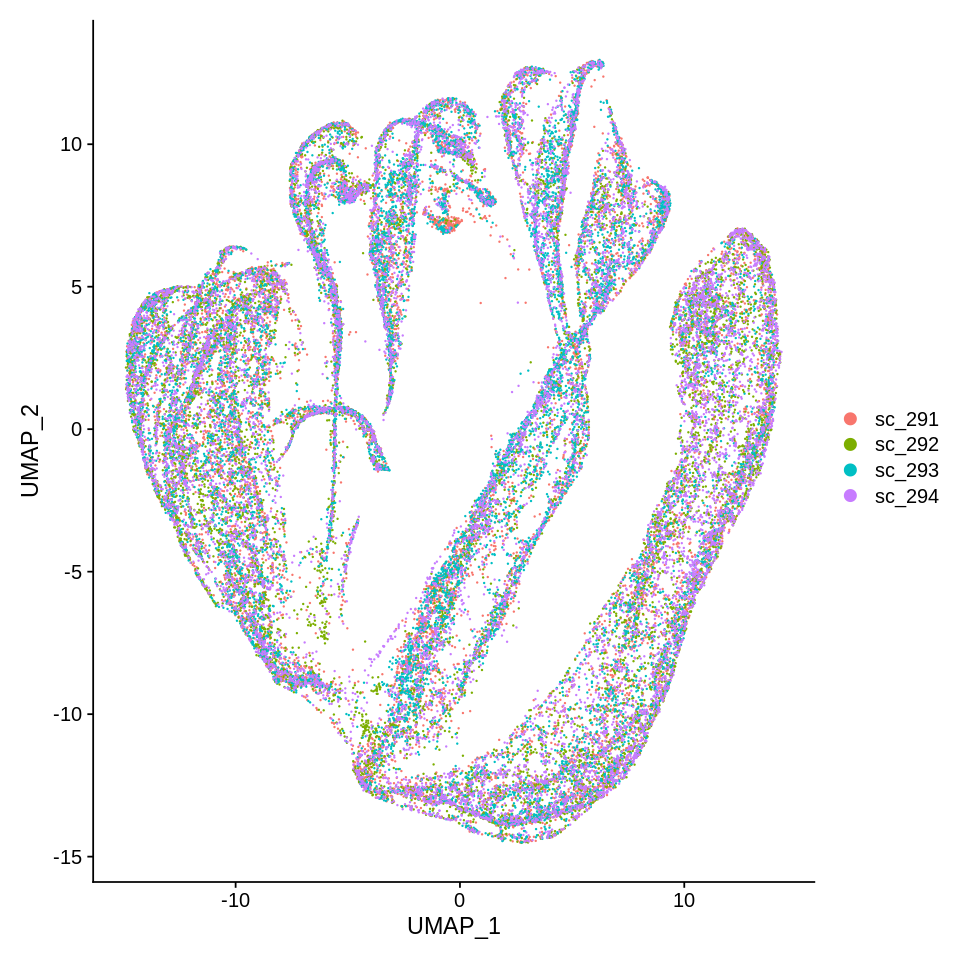

In [47]:
# Check if cluster 6 is removed
options(repr.plot.width=8, repr.plot.height=8)
DimPlot(rc.integrated_sub, label=TRUE)

DimPlot(rc.integrated_sub, group.by = "orig.ident")

In [48]:
unique(rc.integrated_sub$orig.ident)

[1] "sc_291" "sc_292" "sc_293" "sc_294"

In [49]:
# Add metadata for plotting
# Change this to fit your samples

rc.integrated_sub@meta.data <- rc.integrated_sub@meta.data %>%
  mutate(genotype = case_when(orig.ident %in% c("sc_291", "sc_293") ~ "WT",
                              orig.ident %in% c("sc_292", "sc_294") ~ "fer4"))

In [58]:
head(rc.integrated_sub@meta.data, 3)

,orig.ident,nCount_RNA,nFeature_RNA,nCount_spliced_RNA,nFeature_spliced_RNA,nCount_unspliced_RNA,nFeature_unspliced_RNA,percent.mt,percent.cp,nCount_SCT,⋯,pANN_0.25_0.15_464,DF.classifications_0.25_0.15_464,pANN_0.25_0.15_526,DF.classifications_0.25_0.15_526,pANN_0.25_0.15_726,DF.classifications_0.25_0.15_726,integrated_snn_res.0.5,time.anno.Li,celltype.anno.Li,genotype
,<chr>,<dbl>,<int>,<dbl>,<int>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<chr>,<dbl>,<chr>,<dbl>,<chr>,<fct>,<chr>,<fct>,<chr>
AAACCCAAGGACTTCT_4,sc_291,2801,1473,2678,1418,123,91,0.07140307,0.1071046,7949,⋯,NA,NA,NA,NA,NA,NA,4,Elongation,Procambium,WT
AAACCCAAGGTCGTGA_4,sc_291,14092,3995,13277,3834,815,453,0.26256032,0.3690037,9904,⋯,NA,NA,NA,NA,NA,NA,3,Transition Domain,Trichoblast,WT
AAACCCAAGTGCACTT_4,sc_291,4888,2274,4596,2200,292,183,0.22504092,0.3273322,8348,⋯,NA,NA,NA,NA,NA,NA,7,Transition Domain,Trichoblast,WT


In [59]:
# Plot the samples by groups (genotype_treatment)
# Change the factor levels to fit your samples
# You can change the metadata to be grouped by in DimPlot
order <- c("Quiescent Center", "Ground Tissue","Columella", "Lateral Root Cap", "Atrichoblast", "Trichoblast", "Cortex", "Endodermis", "Metaphloem & Companion Cell","Protophloem", "Xylem", "Procambium","Xylem Pole Pericycle","Phloem Pole Pericycle", "Protoxylem", "Metaxylem", "Unknown")
palette <- c("#9400D3", "#DCD0FF","#5AB953", "#BFEF45", "#008080", "#21B6A8", "#82B6FF", "#0000FF","#E6194B", "#DD77EC", "#9A6324", "#FFE119", "#FF9900", "#FFD4E3", "#9A6324", "#DDAA6F", "#EEEEEE")

rc.integrated_sub$celltype.anno.Li <- factor(rc.integrated_sub$celltype.anno.Li, levels = order[sort(match(unique(rc.integrated_sub$celltype.anno.Li),order))])
color <- palette[sort(match(unique(rc.integrated_sub$celltype.anno.Li),order))]

rc.integrated_sub$genotype <- factor(x = rc.integrated_sub$genotype, 
                                  levels = c("WT", "fer4")) # Change the factor levels to fit your samples

p8 <- DimPlot(rc.integrated_sub, 
              reduction = "umap", 
              cols = color,
              split.by = "genotype", # You can change the metadata to be split by
              group.by = "celltype.anno.Li", # You can change the metadata to be grouped by
              combine = TRUE, 
              ncol = 2, # how many columns in the plot
              pt.size = 1)


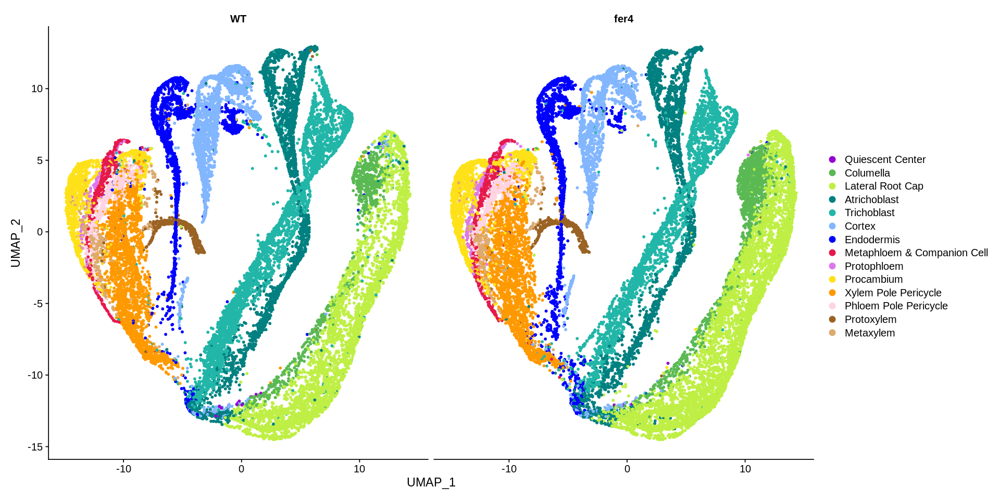

In [62]:
# Plot p8
# You can adjust the width/height
options(repr.plot.width=16, repr.plot.height=8)
p8

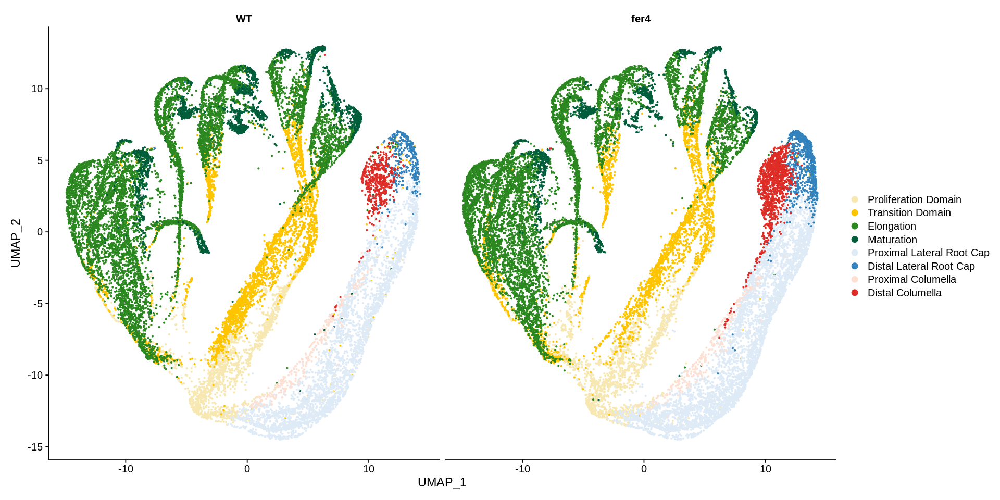

In [65]:
# Plot 
options(repr.plot.width = 16, repr.plot.height = 8)

DimPlot(rc.integrated_sub, reduction = "umap", group.by = "time.anno.Li", order = c("Distal Columella","Proximal Columella","Distal Lateral Root Cap","Proximal Lateral Root Cap","Maturation","Elongation", "Transition Domain", "Proliferation Domain"),
        cols = c('#F7E7B0','#FFC400','#2B871F','#005E3B',"#deebf7", "#3182bd", '#fee0d2','#de2d26'),
        split.by = "genotype", ncol = 2, pt.size = 0.5)


In [67]:
rc.integrated_sub

An object of class Seurat 
72086 features across 44664 samples within 3 assays 
Active assay: integrated (17768 features, 17768 variable features)
 2 other assays present: RNA, SCT
 4 dimensional reductions calculated: pca, umap, umap_3D, umap_2D

In [68]:
head(rc.integrated_sub@meta.data)

,orig.ident,nCount_RNA,nFeature_RNA,nCount_spliced_RNA,nFeature_spliced_RNA,nCount_unspliced_RNA,nFeature_unspliced_RNA,percent.mt,percent.cp,nCount_SCT,⋯,pANN_0.25_0.15_464,DF.classifications_0.25_0.15_464,pANN_0.25_0.15_526,DF.classifications_0.25_0.15_526,pANN_0.25_0.15_726,DF.classifications_0.25_0.15_726,integrated_snn_res.0.5,time.anno.Li,celltype.anno.Li,genotype
,<chr>,<dbl>,<int>,<dbl>,<int>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<chr>,<dbl>,<chr>,<dbl>,<chr>,<fct>,<chr>,<fct>,<fct>
AAACCCAAGGACTTCT_4,sc_291,2801,1473,2678,1418,123,91,0.07140307,0.10710461,7949,⋯,NA,NA,NA,NA,NA,NA,4,Elongation,Procambium,WT
AAACCCAAGGTCGTGA_4,sc_291,14092,3995,13277,3834,815,453,0.26256032,0.36900369,9904,⋯,NA,NA,NA,NA,NA,NA,3,Transition Domain,Trichoblast,WT
AAACCCAAGTGCACTT_4,sc_291,4888,2274,4596,2200,292,183,0.22504092,0.32733224,8348,⋯,NA,NA,NA,NA,NA,NA,7,Transition Domain,Trichoblast,WT
AAACCCAAGTGTTCCA_4,sc_291,11840,3987,11305,3864,535,344,0.43074324,0.32939189,9877,⋯,NA,NA,NA,NA,NA,NA,22,Elongation,Endodermis,WT
AAACCCAGTCTCGGGT_4,sc_291,3564,1622,3409,1568,155,105,0.05611672,0.08417508,8159,⋯,NA,NA,NA,NA,NA,NA,5,Elongation,Phloem Pole Pericycle,WT
AAACCCAGTGCACATT_4,sc_291,7969,2599,7596,2500,373,248,1.56857824,0.62743130,8579,⋯,NA,NA,NA,NA,NA,NA,0,Proximal Lateral Root Cap,Lateral Root Cap,WT


In [69]:
nrow(rc.integrated_sub@meta.data)

[1] 44664

In [70]:
# After saving the Seurat object, comment out this line for safety to prevent accidentally overwriting the saved file    
# Replace with your project name and date. For example, Xu2024_feronia is the study name, and 12S means 12 samples, and 20250126 is the date. 
#saveRDS(rc.integrated_sub, file = "annotated_objects/rds/integrated/Feronia_salinity_timecourse_4S_20251226_seu3_sc291suspiciousClusterRemoved.rds")